# Offshore debottlenecking: more condensate inside the flare limit

The field first screened in notebooks 06 and 07 is ten years into production. The platform is
manned, three-stage, and gas-constrained: the wells now make more gas and water and less
condensate than the design case, and the facility, not the reservoir, sets the rate. The client
wants more condensate without exceeding the flare limit or operating outside the design
envelope.

The next shutdown is four weeks. Work up to four weeks fits the window; four to six weeks is
compressed into it at a labour premium but defers no production; beyond six weeks the shutdown
extends by the excess and the extension defers production. The notebook diagnoses the capacity
chain, sizes the relief and separator checks with the library, screens seven fixes and six
packages, and values them with a ten-year incremental DCF. The field, the history, the costs and
the prices are illustrative, and no number here should be read as a real asset.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import azoth
import azoth.eos
import azoth.process
from azoth.core.errors import InvalidInputError, OutOfRangeError, SolverNotConvergedError

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "text.color": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.alpha": 0.6,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "lines.linewidth": 2.0,
        "font.size": 9,
        "figure.figsize": (6.4, 3.4),
    }
)

q = azoth.ureg.Quantity
R = 8.314462618
T_SC, P_SC = 288.15, 101325.0
MMSCFD_PER_MOL_S = R * T_SC / P_SC * 86400.0 / 28316.846592
BPD_PER_M3 = 1.0 / 0.158987294928

COMPONENTS_HC = [
    "methane",
    "ethane",
    "propane",
    "i-butane",
    "n-butane",
    "i-pentane",
    "n-pentane",
    "n-hexane",
    "n-heptane",
    "n-octane",
    "co2",
    "nitrogen",
]
Z_HC10 = [0.7721, 0.068, 0.045, 0.011, 0.022, 0.0105, 0.013, 0.015, 0.015, 0.0104, 0.012, 0.004]
COMPONENTS = [*COMPONENTS_HC, "water"]
FLARE_COMPONENTS = [name for name in COMPONENTS if name not in ("co2", "water")]
MIXTURE, IDEAL = azoth.eos.components.mixture_of(COMPONENTS)
MOLAR_MASS = [
    azoth.eos.components.component(name).molar_mass.to("kg/mol").magnitude for name in COMPONENTS
]

P_WH, T_WH = 95.0, 363.15
P_HP, P_MP, P_LP = 60.0, 10.0, 2.0
P_EXPORT, P_LIQ, P_RECEPTION = 90.0, 25.0, 20.0
T_HP, T_COOL, T_VC = 354.15, 313.15, 310.93
HC_CURRENT, HC_POTENTIAL, WATER_RATE = 1930.0, 2300.0, 300.0
D_HP, L_HP = 1.96, 7.26
D_MP, L_MP = 1.61, 8.03
D_LP, L_LP = 1.53, 7.64
K_DESIGN, K_UPGRADE = 0.11, 0.14
DRIVER_KW, PUMP_KW = 2300.0, 42.0
PSV_SET, PSV_BACK, PSV_AREA_IN2 = 66.0, 1.5, 6.38
RELIEF_PRESSURE = 72.6
WATER_CAPACITY, WATER_UPGRADE = 3000.0, 6000.0
RETENTION_OIL, RETENTION_WATER = 9.0, 6.5
CGR_VALUE = 25.0

GAS_PRICE, COND_PRICE, DISCOUNT, TAX = 4.0, 70.0, 0.10, 0.25
HEATING_VALUE = 1.05e3
YEARS = 10
G0, DECLINE = 163.4, 0.05
WC_START, WC_END = 0.45, 0.545
BASE_GAS = 137.1
GAS_RECEPTION = 60.0


def norm(z):
    total = float(sum(z))
    return [float(value) / total for value in z]


def mix_streams(n1, z1, n2, z2):
    if n1 <= 0.0:
        return float(n2), list(z2)
    if n2 <= 0.0:
        return float(n1), list(z1)
    total = n1 + n2
    return total, [(n1 * a + n2 * b) / total for a, b in zip(z1, z2, strict=True)]


def as_q(value, unit):
    return value.to(unit) if hasattr(value, "to") else q(value, unit)


def wet_feed(hc_n, water_n, z_hc):
    z_hc = norm(z_hc)
    total = hc_n + water_n
    z = [value * hc_n / total for value in z_hc] + [water_n / total]
    return total, norm(z)


def water_bpd(n_mol_s):
    return n_mol_s * 0.018015 / 1000.0 * 86400.0 * BPD_PER_M3


def boost_gas(n_mol_s, z, p_in, p_out, eta=0.78, t_cool=T_COOL, ratio_max=2.5):
    stages = max(1, math.ceil(math.log(p_out / p_in) / math.log(ratio_max)))
    ratio = (p_out / p_in) ** (1.0 / stages)
    power = duty = 0.0
    n, z = float(n_mol_s), norm(z)
    p, t = p_in, t_cool
    for _ in range(stages):
        comp = azoth.process.compressor(
            COMPONENTS,
            q(n, "mol/s"),
            z,
            q(p, "bar"),
            q(t, "K"),
            eta,
            outlet_pressure=q(p * ratio, "bar"),
        )
        power += comp.power.to("kW").magnitude
        cool = azoth.process.cooler(
            COMPONENTS,
            comp.outlet_n,
            list(comp.outlet_z),
            comp.outlet_p,
            comp.outlet_t,
            outlet_temperature=q(t_cool, "K"),
        )
        duty += abs(cool.outlet_duty.to("kW").magnitude)
        n = cool.outlet_n.to("mol/s").magnitude
        z = norm(list(cool.outlet_z))
        p = cool.outlet_p.to("bar").magnitude
        t = t_cool
    return {"n": n, "z": z, "power_kw": power, "duty_kw": duty, "stages": stages}


def stock_tank(n_mol_s, z):
    z = norm(z)
    flash = azoth.eos.pt_flash(MIXTURE, q(T_SC, "K"), q(P_SC, "bar"), z)
    if flash.phase.value == "all_liquid":
        beta, x = 0.0, z
    elif flash.phase.value in {"all_vapour", "trivial"}:
        beta, x = 1.0, z
    else:
        beta = max(0.0, min(1.0, flash.vapour_fraction or 0.0))
        x = list(flash.x)
    n_liq = n_mol_s * (1.0 - beta)
    n_gas = n_mol_s * beta
    if n_liq <= 0.0:
        return {"bpd": 0.0, "gas_n": n_gas, "gas_z": z}
    m_liq = sum(a * b for a, b in zip(x, MOLAR_MASS, strict=True))
    v_liq = azoth.eos.pr_molar_volume(flash.z_liquid, q(T_SC, "K"), q(P_SC, "bar")).v
    rho = azoth.eos.pr_mass_density(q(m_liq, "kg/mol"), v_liq).rho.to("kg/m**3").magnitude
    bpd = n_liq * m_liq / rho * 86400.0 * BPD_PER_M3
    return {"bpd": bpd, "gas_n": n_gas, "gas_z": z}


def let_down(n_mol_s, z, p_in, t_in, h_in, p_out):
    z = norm(z)
    try:
        valve = azoth.process.throttling_valve(
            COMPONENTS,
            q(n_mol_s, "mol/s"),
            z,
            q(p_in, "bar"),
            as_q(t_in, "K"),
            outlet_pressure=q(p_out, "bar"),
        )
        return {
            "n": valve.outlet_n.to("mol/s").magnitude,
            "z": norm(list(valve.outlet_z)),
            "p": valve.outlet_p,
            "t": valve.outlet_t,
            "h": valve.outlet_h,
            "model": "valve",
        }
    except InvalidInputError:
        flash = azoth.eos.ph_flash(MIXTURE, IDEAL, q(p_out, "bar"), as_q(h_in, "J/mol"), z)
        return {
            "n": n_mol_s,
            "z": z,
            "p": q(p_out, "bar"),
            "t": flash.T,
            "h": as_q(h_in, "J/mol"),
            "model": "ph_flash",
        }


def hp_split(hc_n, water_n):
    total, z = wet_feed(hc_n, water_n, Z_HC10)
    try:
        multi = azoth.eos.tp_multiflash(MIXTURE, q(T_HP, "K"), q(P_HP, "bar"), z)
        vessel = azoth.process.three_phase_separator(
            COMPONENTS,
            q(total, "mol/s"),
            z,
            q(P_HP, "bar"),
            q(T_HP, "K"),
            q(0.0, "bar"),
            gas_in_aqueous=0.0,
            gas_in_oil=0.0,
            oil_in_aqueous=0.0,
            oil_in_gas=0.0,
            aqueous_in_gas=0.0,
            aqueous_in_oil=0.0,
            internal_diameter=q(D_HP, "m"),
            separator_length=q(L_HP, "m"),
            nll_fraction=0.5,
            nil_fraction=0.2,
        )
        return {
            "mode": "three_phase",
            "total": total,
            "z": z,
            "vapour_n": vessel.vapour_n.to("mol/s").magnitude,
            "vapour_z": norm(list(vessel.vapour_z)),
            "light_liquid_n": vessel.light_liquid_n.to("mol/s").magnitude,
            "light_liquid_z": norm(list(vessel.light_liquid_z)),
            "light_liquid_h": vessel.light_liquid_h,
            "light_liquid_t": vessel.light_liquid_t,
            "heavy_liquid_n": vessel.heavy_liquid_n.to("mol/s").magnitude,
            "heavy_liquid_z": norm(list(vessel.heavy_liquid_z)),
            "oil_retention_s": vessel.oil_retention_time.to("s").magnitude,
            "water_retention_s": vessel.water_retention_time.to("s").magnitude,
            "settling_s": vessel.interface_settling_time.to("s").magnitude,
            "settling_ok": vessel.settling_time_sufficient,
            "phase_count": multi.phase_count,
            "phase_fractions": multi.phase_fractions,
            "seeded": multi.seeded,
        }
    except (InvalidInputError, OutOfRangeError, SolverNotConvergedError):
        dry_z = [*norm(Z_HC10), 0.0]
        sep = azoth.process.separator(
            COMPONENTS,
            q(hc_n, "mol/s"),
            dry_z,
            q(P_HP, "bar"),
            q(T_HP, "K"),
            q(0.0, "bar"),
            0.0,
        )
        return {
            "mode": "free_water",
            "total": total,
            "z": z,
            "vapour_n": sep.vapour_n.to("mol/s").magnitude,
            "vapour_z": norm(list(sep.vapour_z)),
            "light_liquid_n": sep.liquid_n.to("mol/s").magnitude,
            "light_liquid_z": norm(list(sep.liquid_z)),
            "light_liquid_h": sep.liquid_h,
            "light_liquid_t": sep.liquid_t,
            "heavy_liquid_n": water_n,
            "heavy_liquid_z": [0.0] * 12 + [1.0],
            "oil_retention_s": None,
            "water_retention_s": None,
            "settling_s": None,
            "settling_ok": False,
            "phase_count": 2,
            "phase_fractions": None,
            "seeded": "free_water",
        }


def run_train(hc_n, water_n, k_hp=K_DESIGN):
    hp = hp_split(hc_n, water_n)
    hp_n, hp_z = hp["vapour_n"], hp["vapour_z"]
    hp_m = sum(a * b for a, b in zip(hp_z, MOLAR_MASS, strict=True))
    hp_mass = hp_n * hp_m
    assess = azoth.process.separator_capacity_assessment(
        COMPONENTS,
        q(hp_n, "mol/s"),
        hp_z,
        q(P_HP, "bar"),
        q(T_HP, "K"),
        q(0.0, "bar"),
        0.0,
        q(D_HP, "m"),
        q(k_hp, "m/s"),
        "horizontal",
        0.2,
        "as-built HP separator data sheet",
    )
    mp_in = let_down(
        hp["light_liquid_n"],
        hp["light_liquid_z"],
        P_HP,
        hp["light_liquid_t"],
        hp["light_liquid_h"],
        P_MP,
    )
    mp = azoth.process.separator(
        COMPONENTS,
        q(mp_in["n"], "mol/s"),
        mp_in["z"],
        q(P_MP, "bar"),
        mp_in["t"],
        q(0.0, "bar"),
        0.0,
    )
    lp_in = let_down(
        mp.liquid_n.to("mol/s").magnitude,
        list(mp.liquid_z),
        P_MP,
        mp.liquid_t,
        mp.liquid_h,
        P_LP,
    )
    lp = azoth.process.separator(
        COMPONENTS,
        q(lp_in["n"], "mol/s"),
        lp_in["z"],
        q(P_LP, "bar"),
        lp_in["t"],
        q(0.0, "bar"),
        0.0,
    )
    gas_n, gas_z = 0.0, None
    power = duty = 0.0
    for n, zz, p in [
        (hp_n, hp_z, P_HP),
        (mp.vapour_n.to("mol/s").magnitude, norm(list(mp.vapour_z)), P_MP),
        (lp.vapour_n.to("mol/s").magnitude, norm(list(lp.vapour_z)), P_LP),
    ]:
        boost = boost_gas(n, zz, p, P_EXPORT)
        power += boost["power_kw"]
        duty += boost["duty_kw"]
        gas_n, gas_z = mix_streams(gas_n, gas_z, boost["n"], boost["z"])
    liquid_n = lp.liquid_n.to("mol/s").magnitude
    liquid_z = norm(list(lp.liquid_z))
    tank = stock_tank(liquid_n, liquid_z)
    sales_n = gas_n + tank["gas_n"]
    if tank["gas_n"] > 0.0:
        gas_z = mix_streams(gas_n, gas_z, tank["gas_n"], tank["gas_z"])[1]
    pump_kw = pump_head = 0.0
    if lp.liquid_p.to("bar").magnitude < P_LIQ - 0.1:
        pump = azoth.process.pump(
            COMPONENTS,
            q(liquid_n, "mol/s"),
            liquid_z,
            lp.liquid_p,
            lp.liquid_t,
            0.75,
            outlet_pressure=q(P_LIQ, "bar"),
        )
        pump_kw = pump.power.to("kW").magnitude
        pump_head = pump.head.to("m").magnitude if pump.head is not None else 0.0
    water = water_bpd(hp["heavy_liquid_n"])
    gas_mmscfd = sales_n * MMSCFD_PER_MOL_S
    return {
        "hp": hp,
        "mp": mp,
        "lp": lp,
        "tank": tank,
        "gas_mmscfd": gas_mmscfd,
        "bpd": tank["bpd"],
        "water_bpd": water,
        "cgr": tank["bpd"] / gas_mmscfd if gas_mmscfd > 0.0 else 0.0,
        "water_cut": water / (water + tank["bpd"]),
        "power_kw": power,
        "duty_kw": duty,
        "pump_kw": pump_kw,
        "pump_head": pump_head,
        "hp_util": assess.utilization,
        "hp_k": k_hp * assess.utilization,
        "oil_retention_s": hp["oil_retention_s"],
        "water_retention_s": hp["water_retention_s"],
        "settling_s": hp["settling_s"],
        "settling_ok": hp["settling_ok"],
        "mode": hp["mode"],
        "mp_model": mp_in["model"],
        "lp_model": lp_in["model"],
        "hp_mass": hp_mass,
        "hp_n": hp_n,
        "hp_z": hp_z,
        "gas_n": gas_n,
        "gas_z": gas_z,
        "sales_n": sales_n,
        "liquid_n": liquid_n,
        "liquid_z": liquid_z,
    }


def flare_z_of(z):
    return norm([z[i] for i, name in enumerate(COMPONENTS) if name not in ("co2", "water")])


def flare_case(n, z, design_mass, design_molar, ground_distance=100.0):
    return azoth.process.flare(
        FLARE_COMPONENTS,
        q(n, "mol/s"),
        flare_z_of(z),
        q(P_HP, "bar"),
        q(T_HP, "K"),
        ground_distance=q(ground_distance, "m"),
        radiation_flux_threshold=q(4.73, "kW/m**2"),
        design_mass_flow_capacity=q(design_mass, "kg/s"),
        design_molar_flow_capacity=q(design_molar, "mol/s"),
    )


def relief_and_psv(mass, z, label):
    blocked = azoth.process.blocked_outlet_relief(
        COMPONENTS,
        z,
        q(mass, "kg/s"),
        q(RELIEF_PRESSURE, "bar"),
        q(T_HP, "K"),
        scenario_name=label,
    )
    psv = azoth.process.psv_sizing(
        "gas",
        q(PSV_SET, "bar"),
        0.10,
        q(PSV_BACK, "bar"),
        mass_flow=blocked.relief_rate,
        temperature=q(T_HP, "K"),
        molar_mass=blocked.molar_mass,
        compressibility=blocked.compressibility,
        specific_heat_ratio=blocked.specific_heat_ratio,
        orifice_area=q(PSV_AREA_IN2, "inch**2").to("m**2"),
        capacity_discharge_coefficient=0.975,
    )
    return blocked, psv


print("azoth", azoth.__version__, "| backends", sorted(azoth.backends()))

azoth 0.1.4 | backends ['python', 'rust']


## 1. The field at year ten

The platform is the 60/10/2 three-stage manned platform from notebook 07: 137 MMscfd of sales
gas at design, about 6,100 bbl/d of stock-tank liquid, and no produced water. The actual history
diverged from the 07 forecast. Pressure support held better than planned but the GOR rose faster,
so gas sits at the facility limit while condensate falls and water breaks through. The wells can
still deliver about 2,300 mol/s of hydrocarbon, 163 MMscfd of gas, so the facility is the
constraint.

The fluid at year ten is gassier: the C7+ fraction is lower and the condensate yield has fallen
from 44 to about 21 bbl/MMscf. Water is 2,782 bbl/d against 2,936 bbl/d of condensate, a 48.7 %
cut. The HP separator is the first stage of a three-phase retrofit: the water draw-off is at the
HP vessel, and the MP and LP stages are two-phase.

In [2]:
current_split = hp_split(HC_CURRENT, WATER_RATE)
potential_split = hp_split(HC_POTENTIAL, WATER_RATE)

phase_rows = [
    {
        "phase": "vapour",
        "current mol/s": current_split["vapour_n"],
        "current share %": current_split["vapour_n"] / current_split["total"] * 100.0,
        "potential mol/s": potential_split["vapour_n"],
    },
    {
        "phase": "oil",
        "current mol/s": current_split["light_liquid_n"],
        "current share %": current_split["light_liquid_n"] / current_split["total"] * 100.0,
        "potential mol/s": potential_split["light_liquid_n"],
    },
    {
        "phase": "water",
        "current mol/s": current_split["heavy_liquid_n"],
        "current share %": current_split["heavy_liquid_n"] / current_split["total"] * 100.0,
        "potential mol/s": potential_split["heavy_liquid_n"],
    },
]
display(pd.DataFrame(phase_rows))
print(
    "multiflash:",
    current_split["phase_count"],
    "phases,",
    current_split["seeded"],
    "| fractions (unlabelled order):",
    tuple(round(value, 3) for value in current_split["phase_fractions"]),
)
print(
    "HP retention: oil",
    round(current_split["oil_retention_s"] / 60.0, 2),
    "min, water",
    round(current_split["water_retention_s"] / 60.0, 2),
    "min; interface settling",
    round(current_split["settling_s"], 1),
    "s, sufficient:",
    current_split["settling_ok"],
)
print("HP split mode:", current_split["mode"])

robust_rows = [
    {
        "water mol %": WATER_RATE / (HC_CURRENT + WATER_RATE) * 100.0,
        "water mol/s": WATER_RATE,
        "water bbl/d": water_bpd(current_split["heavy_liquid_n"]),
        "phases": current_split["phase_count"],
        "water retention min": current_split["water_retention_s"] / 60.0,
    }
]
for water_mol in (0.16, 0.18):
    water_n = HC_CURRENT * water_mol / (1.0 - water_mol)
    split = hp_split(HC_CURRENT, water_n)
    robust_rows.append(
        {
            "water mol %": water_mol * 100.0,
            "water mol/s": water_n,
            "water bbl/d": water_bpd(split["heavy_liquid_n"]),
            "phases": split["phase_count"],
            "water retention min": (split["water_retention_s"] or 0.0) / 60.0,
        }
    )
display(pd.DataFrame(robust_rows))
print("The as-built feed is 13.45 mol % water; 16-18 mol % is a robustness check, not the design.")

,phase,current mol/s,current share %,potential mol/s
0,vapour,1869.188310,83.820104,2227.530679
1,oil,76.623221,3.436019,91.312615
2,water,284.188469,12.743878,281.156706


multiflash: 3 phases, stability_seeded | fractions (unlabelled order): (0.034, 0.838, 0.127)
HP retention: oil 10.92 min, water 7.83 min; interface settling 17.1 s, sufficient: False
HP split mode: three_phase


,water mol %,water mol/s,water bbl/d,phases,water retention min
0,13.452915,300.000000,2782.223670,3,7.829436
1,16.000000,367.619048,3444.224743,3,6.324571
2,18.000000,423.658537,3992.860122,3,5.455549


The as-built feed is 13.45 mol % water; 16-18 mol % is a robustness check, not the design.


## 2. The train and the let-down

The HP oil is two-phase at 60 bara, so the throttling valve refuses it; the MP stage uses an
isenthalpic `ph_flash` at 10 bara and then a separator. The MP liquid is single-phase at 10 bara,
so the LP stage can use the valve. Each stage gas is cooled to 313.15 K and compressed to 90 bara
in equal-ratio stages no larger than 2.5.

The train reproduces the design gas rate at the year-ten point and gives the product slate the
rest of the study uses. The HP separator's interface settling is 17.1 s against the class's
one-minute check, so the produced-water package must include a coalescer; that is a performance
requirement, not a capacity one, and it does not change the gas cap.

In [3]:
current = run_train(HC_CURRENT, WATER_RATE)
potential = run_train(HC_POTENTIAL, WATER_RATE)

stage_rows = [
    {"stage": "HP", "stream": "vapour", "mol/s": current["hp"]["vapour_n"]},
    {"stage": "HP", "stream": "oil", "mol/s": current["hp"]["light_liquid_n"]},
    {"stage": "HP", "stream": "water", "mol/s": current["hp"]["heavy_liquid_n"]},
    {"stage": "MP", "stream": "vapour", "mol/s": current["mp"].vapour_n.to("mol/s").magnitude},
    {"stage": "MP", "stream": "liquid", "mol/s": current["mp"].liquid_n.to("mol/s").magnitude},
    {"stage": "LP", "stream": "vapour", "mol/s": current["lp"].vapour_n.to("mol/s").magnitude},
    {"stage": "LP", "stream": "liquid", "mol/s": current["lp"].liquid_n.to("mol/s").magnitude},
]
display(pd.DataFrame(stage_rows))

product_rows = [
    {
        "quantity": "sales gas, MMscfd",
        "current": current["gas_mmscfd"],
        "potential": potential["gas_mmscfd"],
    },
    {
        "quantity": "stock-tank condensate, bbl/d",
        "current": current["bpd"],
        "potential": potential["bpd"],
    },
    {
        "quantity": "produced water, bbl/d",
        "current": current["water_bpd"],
        "potential": potential["water_bpd"],
    },
    {
        "quantity": "water cut, %",
        "current": current["water_cut"] * 100.0,
        "potential": potential["water_cut"] * 100.0,
    },
    {"quantity": "CGR, bbl/MMscf", "current": current["cgr"], "potential": potential["cgr"]},
    {
        "quantity": "compression, kW",
        "current": current["power_kw"],
        "potential": potential["power_kw"],
    },
    {
        "quantity": "cooler duty, kW",
        "current": current["duty_kw"],
        "potential": potential["duty_kw"],
    },
    {
        "quantity": "HP separator gas load, %",
        "current": current["hp_util"] * 100.0,
        "potential": potential["hp_util"] * 100.0,
    },
    {
        "quantity": "oil retention, min",
        "current": (current["oil_retention_s"] or 0.0) / 60.0,
        "potential": (potential["oil_retention_s"] or 0.0) / 60.0,
    },
    {
        "quantity": "water retention, min",
        "current": (current["water_retention_s"] or 0.0) / 60.0,
        "potential": (potential["water_retention_s"] or 0.0) / 60.0,
    },
    {"quantity": "pump, kW", "current": current["pump_kw"], "potential": potential["pump_kw"]},
]
display(pd.DataFrame(product_rows))
print(
    "let-down models: HP",
    current["mode"],
    "| MP",
    current["mp_model"],
    "| LP",
    current["lp_model"],
    "| settling sufficient:",
    current["settling_ok"],
)

BASE_GAS = current["gas_mmscfd"]
G0 = potential["gas_mmscfd"]
CGR_VALUE = current["cgr"]
WC_START = current["water_cut"]
WC_END = 0.57
print(
    "DCF basis: base",
    round(BASE_GAS, 2),
    "potential",
    round(G0, 2),
    "CGR",
    round(CGR_VALUE, 2),
    "WC",
    round(WC_START, 3),
)

,stage,stream,mol/s
0,HP,vapour,1869.188310
1,HP,oil,76.623221
2,HP,water,284.188469
3,MP,vapour,23.470075
4,MP,liquid,53.153146
5,LP,vapour,7.452050
6,LP,liquid,45.701096


,quantity,current,potential
0,"sales gas, MMscfd",137.083093,163.363311
1,"stock-tank condensate, bbl/d",2935.835236,3498.662597
2,"produced water, bbl/d",2782.223670,2752.542510
3,"water cut, %",48.656786,44.032190
4,"CGR, bbl/MMscf",21.416465,21.416453
5,"compression, kW",2256.438668,2689.020699
6,"cooler duty, kW",3885.311885,4630.165506
7,"HP separator gas load, %",99.771967,118.899277
8,"oil retention, min",10.915526,9.159553
9,"water retention, min",7.829436,7.913862


let-down models: HP three_phase | MP ph_flash | LP valve | settling sufficient: False
DCF basis: base 137.08 potential 163.36 CGR 21.42 WC 0.487


## 3. The capacity chain

The first limit is not the compressor. At the year-ten point the HP separator is at 99.8 % of its
Souders-Brown gas load, the export compression at 98 % of its driver, the produced-water plant at
93 %, and the flare at 91 %. The gas trunk is at 76 % and the PSV at 74 %; the pump and the liquid
line have ample headroom. The separator is the first constraint, the compressor the second, and
the water plant the hidden third: a gas-side package that ignores the water plant cannot use the
capacity it buys.

The cap table is the same fact in the other direction: the gas rate at which each constraint
reaches its limit. The HP separator allows 137.4 MMscfd, the compressor 139.7, the water plant
147.8 and the flare 150.5; the gas line and PSV are beyond 175.

,constraint,utilisation %
7,liquid line,15.255537
6,pump power,48.507684
5,PSV orifice,73.472826
4,gas line,76.226075
3,flare,91.098653
2,produced water,92.740789
1,compressor power,98.106029
0,separator gas load,99.771967


HP K 0.1097 m/s against 0.11 | retention oil 10.92 min, water 7.83 min against 9.0 and 6.5 | settling 17.1 s sufficient: False
line arrivals: gas 71.6 bara now, 61.7 at the potential; liquid 24.24 bara now, 23.94 at the potential


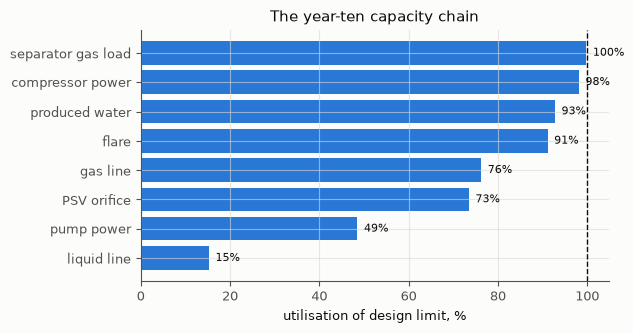

In [4]:
base_gas = current["gas_mmscfd"]
blocked_current, psv_current = relief_and_psv(
    current["hp_mass"], current["hp_z"], "HP blocked outlet"
)
flare_design_mass = current["hp_mass"] / 0.92
flare_design_molar = current["hp_n"] / 0.92
flare_current = flare_case(current["hp_n"], current["hp_z"], flare_design_mass, flare_design_molar)

gas_line_current = azoth.eos.pipe_beggs_and_brills(
    COMPONENTS,
    current["sales_n"],
    current["gas_z"],
    q(P_EXPORT, "bar"),
    q(T_COOL, "K"),
    q(15000.0, "m"),
    q(0.3048, "m"),
    q(0.0, "m"),
    30,
    q(4.6e-5, "m"),
)
gas_line_potential = azoth.eos.pipe_beggs_and_brills(
    COMPONENTS,
    potential["sales_n"],
    potential["gas_z"],
    q(P_EXPORT, "bar"),
    q(T_COOL, "K"),
    q(15000.0, "m"),
    q(0.3048, "m"),
    q(0.0, "m"),
    30,
    q(4.6e-5, "m"),
)
liquid_line_current = azoth.eos.pipe_beggs_and_brills(
    COMPONENTS,
    current["liquid_n"],
    current["liquid_z"],
    q(P_LIQ, "bar"),
    q(T_COOL, "K"),
    q(15000.0, "m"),
    q(0.1524, "m"),
    q(0.0, "m"),
    30,
    q(4.6e-5, "m"),
)
liquid_line_potential = azoth.eos.pipe_beggs_and_brills(
    COMPONENTS,
    potential["liquid_n"],
    potential["liquid_z"],
    q(P_LIQ, "bar"),
    q(T_COOL, "K"),
    q(15000.0, "m"),
    q(0.1524, "m"),
    q(0.0, "m"),
    30,
    q(4.6e-5, "m"),
)

gas_line_drop = P_EXPORT - gas_line_current.outlet_pressure.to("bar").magnitude
gas_line_cap = base_gas * ((P_EXPORT - GAS_RECEPTION) / gas_line_drop) ** (1.0 / 1.8)
liquid_line_drop = P_LIQ - liquid_line_current.outlet_pressure.to("bar").magnitude

util_rows = [
    {"constraint": "separator gas load", "utilisation %": current["hp_util"] * 100.0},
    {"constraint": "compressor power", "utilisation %": current["power_kw"] / DRIVER_KW * 100.0},
    {
        "constraint": "produced water",
        "utilisation %": current["water_bpd"] / WATER_CAPACITY * 100.0,
    },
    {"constraint": "flare", "utilisation %": flare_current.mass_utilization * 100.0},
    {"constraint": "gas line", "utilisation %": base_gas / gas_line_cap * 100.0},
    {
        "constraint": "PSV orifice",
        "utilisation %": psv_current.required_area_in2 / PSV_AREA_IN2 * 100.0,
    },
    {"constraint": "pump power", "utilisation %": current["pump_kw"] / PUMP_KW * 100.0},
    {
        "constraint": "liquid line",
        "utilisation %": liquid_line_drop / (P_LIQ - P_RECEPTION) * 100.0,
    },
]
util = pd.DataFrame(util_rows).sort_values("utilisation %")
display(util)
print(
    "HP K",
    round(current["hp_k"], 4),
    "m/s against",
    K_DESIGN,
    "| retention oil",
    round((current["oil_retention_s"] or 0.0) / 60.0, 2),
    "min, water",
    round((current["water_retention_s"] or 0.0) / 60.0, 2),
    "min against",
    RETENTION_OIL,
    "and",
    RETENTION_WATER,
    "| settling",
    round(current["settling_s"], 1),
    "s sufficient:",
    current["settling_ok"],
)
print(
    "line arrivals: gas",
    round(gas_line_current.outlet_pressure.to("bar").magnitude, 1),
    "bara now,",
    round(gas_line_potential.outlet_pressure.to("bar").magnitude, 1),
    "at the potential;",
    "liquid",
    round(liquid_line_current.outlet_pressure.to("bar").magnitude, 2),
    "bara now,",
    round(liquid_line_potential.outlet_pressure.to("bar").magnitude, 2),
    "at the potential",
)

fig, ax = plt.subplots()
colors = [PALETTE[1] if value > 100.0 else PALETTE[0] for value in util["utilisation %"]]
ax.barh(util["constraint"], util["utilisation %"], color=colors)
ax.axvline(100.0, color=INK, linestyle="--", linewidth=1.0)
ax.set_xlabel("utilisation of design limit, %")
ax.set_title("The year-ten capacity chain")
for index, value in enumerate(util["utilisation %"]):
    ax.text(value + 1.5, index, f"{value:.0f}%", va="center", color=INK, fontsize=8)
fig.tight_layout()
plt.show()
plt.close(fig)

## 4. The relief case

The governing relief case is the HP separator blocked outlet: the full HP vapour inflow, flashed at
the relieving pressure, 42.63 kg/s. The fire case is 0.54 kg/s, so the blocked outlet governs by
nearly two orders of magnitude. The installed P orifice has 6.38 in² against a required 4.69 in²,
73.6 % of its capacity; at +18 % gas it needs 5.53 in² and is still a P orifice at 86.7 %. The
PSV is not the gate.

The flare is. The existing flare is at 91 % of its mass capacity; a +18 % gas rate takes it to
107 % and overloads it. A 25 % flare and header upgrade takes the same load to 86 %; a HIPPS that
cuts the blocked-outlet case by 35 % takes it to 70 %. The radiation distance to 4.73 kW/m² rises
from 75 m to 82 m at +18 %, and falls to 64 m with the HIPPS. The $12M relief fix is therefore a
flare and header upgrade, not a PSV change.

,case,relief kg/s,PSV required in2,PSV utilisation %,flare mass utilisation %,flare overloaded,radiation distance m
0,current,42.633901,4.687566,73.472826,91.098653,False,74.959298
1,+18% gas,50.308003,5.531328,86.697935,107.496410,True,82.415397
2,"+18%, flare +25%",50.308003,5.531328,86.697935,85.997128,False,82.415397
3,"+18%, HIPPS -35%",32.700202,3.595363,56.353658,69.872667,False,64.031191


fire case 0.539 kg/s | simultaneous network 42.634 kg/s, peak 42.634 kg/s
PSV: required 4.69 in2, recommended P selected 6.38 in2, capacity 58.0 kg/s


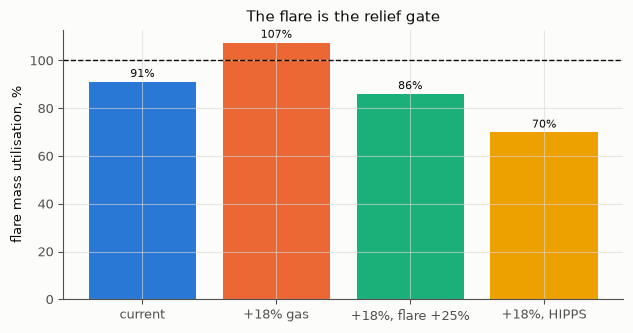

In [5]:
blocked_18, psv_18 = relief_and_psv(
    current["hp_mass"] * 1.18, current["hp_z"], "HP blocked outlet +18%"
)
blocked_hipps, psv_hipps = relief_and_psv(
    current["hp_mass"] * 1.18 * 0.65, current["hp_z"], "HP blocked outlet +18% HIPPS"
)

fire = azoth.process.fire_case_relief(
    True,
    True,
    vessel_diameter=q(D_HP, "m"),
    wetted_height=q(0.98, "m"),
    latent_heat=350000.0,
    relieving_temperature=q(T_HP, "K"),
)
network = azoth.process.relief_disposal_network(
    [
        {
            "item_name": "HP blocked outlet",
            "cause": "blocked_outlet",
            "phase": "vapour",
            "mass_flow": blocked_current.relief_rate,
            "simultaneous": True,
        },
        {
            "item_name": "HP fire",
            "cause": "fire",
            "phase": "vapour",
            "mass_flow": fire.relief_rate,
            "simultaneous": False,
        },
    ]
)
flare_18 = flare_case(
    current["hp_n"] * 1.18, current["hp_z"], flare_design_mass, flare_design_molar
)
flare_25 = flare_case(
    current["hp_n"] * 1.18,
    current["hp_z"],
    flare_design_mass * 1.25,
    flare_design_molar * 1.25,
)
flare_hipps = flare_case(
    current["hp_n"] * 1.18 * 0.65,
    current["hp_z"],
    flare_design_mass,
    flare_design_molar,
)

relief_rows = [
    {
        "case": "current",
        "relief kg/s": blocked_current.relief_rate.to("kg/s").magnitude,
        "PSV required in2": psv_current.required_area_in2,
        "PSV utilisation %": psv_current.required_area_in2 / PSV_AREA_IN2 * 100.0,
        "flare mass utilisation %": flare_current.mass_utilization * 100.0,
        "flare overloaded": flare_current.overloaded,
        "radiation distance m": flare_current.radiation_distance.to("m").magnitude,
    },
    {
        "case": "+18% gas",
        "relief kg/s": blocked_18.relief_rate.to("kg/s").magnitude,
        "PSV required in2": psv_18.required_area_in2,
        "PSV utilisation %": psv_18.required_area_in2 / PSV_AREA_IN2 * 100.0,
        "flare mass utilisation %": flare_18.mass_utilization * 100.0,
        "flare overloaded": flare_18.overloaded,
        "radiation distance m": flare_18.radiation_distance.to("m").magnitude,
    },
    {
        "case": "+18%, flare +25%",
        "relief kg/s": blocked_18.relief_rate.to("kg/s").magnitude,
        "PSV required in2": psv_18.required_area_in2,
        "PSV utilisation %": psv_18.required_area_in2 / PSV_AREA_IN2 * 100.0,
        "flare mass utilisation %": flare_25.mass_utilization * 100.0,
        "flare overloaded": flare_25.overloaded,
        "radiation distance m": flare_25.radiation_distance.to("m").magnitude,
    },
    {
        "case": "+18%, HIPPS -35%",
        "relief kg/s": blocked_hipps.relief_rate.to("kg/s").magnitude,
        "PSV required in2": psv_hipps.required_area_in2,
        "PSV utilisation %": psv_hipps.required_area_in2 / PSV_AREA_IN2 * 100.0,
        "flare mass utilisation %": flare_hipps.mass_utilization * 100.0,
        "flare overloaded": flare_hipps.overloaded,
        "radiation distance m": flare_hipps.radiation_distance.to("m").magnitude,
    },
]
display(pd.DataFrame(relief_rows))
print(
    "fire case",
    round(fire.relief_rate.to("kg/s").magnitude, 3),
    "kg/s | simultaneous network",
    round(network.total_simultaneous.to("kg/s").magnitude, 3),
    "kg/s, peak",
    round(network.peak_single.to("kg/s").magnitude, 3),
    "kg/s",
)
print(
    "PSV: required",
    round(psv_current.required_area_in2, 2),
    "in2, recommended",
    psv_current.recommended_orifice,
    "selected",
    psv_current.selected_area_in2,
    "in2, capacity",
    round(psv_current.mass_flow_capacity.to("kg/s").magnitude, 1),
    "kg/s",
)

fig, ax = plt.subplots()
flare_cases = ["current", "+18% gas", "+18%, flare +25%", "+18%, HIPPS"]
flare_values = [flare_current, flare_18, flare_25, flare_hipps]
values = [value.mass_utilization * 100.0 for value in flare_values]
ax.bar(flare_cases, values, color=[PALETTE[0], PALETTE[1], PALETTE[2], PALETTE[3]])
ax.axhline(100.0, color=INK, linestyle="--", linewidth=1.0)
ax.set_ylabel("flare mass utilisation, %")
ax.set_title("The flare is the relief gate")
for index, value in enumerate(values):
    ax.text(index, value + 2.0, f"{value:.0f}%", ha="center", color=INK, fontsize=8)
fig.tight_layout()
plt.show()
plt.close(fig)

In [6]:
npd = azoth.process.nog070_sil_determination("hipps_pipeline", 1e-4)
sil = azoth.process.sil_verification(1e-4, 3.0, "1oo2", 8760.0)
ppp = azoth.process.pipeline_pressure_protection(
    q(95.0, "bar"), q(66.0, "bar"), 1.1, q(64.0, "bar"), q(66.0, "bar")
)
s001 = azoth.process.s001_secondary_pressure_protection(
    maximum_event_pressure=72.6,
    design_pressure=66.0,
    test_pressure=99.0,
    demand_frequency_per_year=1e-4,
    target_frequency_per_year=1e-3,
    relief_leakage_assessed=True,
    relief_leakage_to_safe_location=True,
    proof_test_interval_months=12,
)
hipps_rows = [
    {"check": "NOG-070 minimum SIL", "result": npd.minimum_sil, "verdict": "catalogue"},
    {
        "check": "NOG-070 achieved SIL",
        "result": npd.achieved_sil,
        "verdict": "compliant" if npd.compliant else "not compliant",
    },
    {
        "check": "SIL verification, 1oo2",
        "result": sil.achieved_sil,
        "verdict": "passed" if sil.verification_passed else "failed",
    },
    {
        "check": "pipeline max incidental, bara",
        "result": ppp.max_incidental_pressure.to("bar").magnitude,
        "verdict": ppp.verdict,
    },
    {
        "check": "S-001 secondary protection",
        "result": "acceptable" if s001.acceptable else "not acceptable",
        "verdict": "",
    },
]
display(pd.DataFrame(hipps_rows))
print(
    "SIL detail: HFT",
    sil.hardware_fault_tolerance,
    "DC",
    sil.diagnostic_coverage,
    "| pipeline protection adequate:",
    ppp.protection_adequate,
)
print("The 35% relief reduction is a study assumption; the safety case is outside the shutdown.")

,check,result,verdict
0,NOG-070 minimum SIL,3.0,catalogue
1,NOG-070 achieved SIL,3.0,compliant
2,"SIL verification, 1oo2",3.0,passed
3,"pipeline max incidental, bara",72.6,TWO_BARRIERS_REQUIRED
4,S-001 secondary protection,acceptable,


SIL detail: HFT 1.0 DC 0.6 | pipeline protection adequate: True
The 35% relief reduction is a study assumption; the safety case is outside the shutdown.


## 5. What a single fix can and cannot do

The HIPPS is a real alternative to the flare upgrade: the SIL-3 function is verifiable against
NOG-070 and S-001, and the two-barrier pipeline check is satisfied. It costs $6M against the
flare's $12M, and its relief work is two weeks against four; both packages are set by the
four-week water upgrade. The 35 % relief-case reduction is the study's assumption, not a library
output; the safety case is a non-shutdown activity and a schedule risk.

The capacity caps make the chain visible. The separator internals lift their cap from 137 to 175;
the compressor re-rate lifts its cap from 140 to 162; the flare upgrade lifts its cap from 150 to
188, and the HIPPS lifts it to 232. The water plant is the link nobody priced: without its upgrade
the package cannot pass 148 MMscfd.

,constraint,current cap,after cap,fix
0,HP separator,137.396402,174.868148,internals
1,compressor,139.729529,161.758049,re-rate
2,flare,150.477629,188.097036,flare/header (HIPPS 232)
3,water plant,147.813162,295.626324,water upgrade
4,gas line,179.837532,179.837532,none
5,PSV,186.378687,186.378687,none
6,oil retention,166.259341,166.259341,coalescer
7,water retention,165.120508,165.120508,coalescer


gas-side cap 147.8 MMscfd; package cap 161.8 MMscfd; HIPPS cap 161.8 MMscfd; potential 163.4 MMscfd


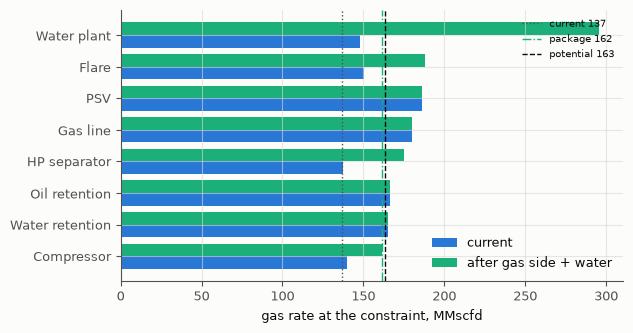

In [7]:
caps = {
    "HP separator": base_gas / current["hp_util"],
    "Compressor": base_gas / (current["power_kw"] / DRIVER_KW),
    "Flare": base_gas / flare_current.mass_utilization,
    "Water plant": base_gas / (current["water_bpd"] / WATER_CAPACITY),
    "Oil retention": base_gas * (current["oil_retention_s"] / 60.0) / RETENTION_OIL,
    "Water retention": base_gas * (current["water_retention_s"] / 60.0) / RETENTION_WATER,
    "PSV": base_gas * psv_current.mass_flow_capacity.to("kg/s").magnitude / current["hp_mass"],
    "Gas line": gas_line_cap,
}
fixed_caps = {
    "HP separator": caps["HP separator"] * K_UPGRADE / K_DESIGN,
    "Compressor": base_gas * 1.18,
    "Flare": caps["Flare"] * 1.25,
    "Water plant": caps["Water plant"] * WATER_UPGRADE / WATER_CAPACITY,
    "Oil retention": caps["Oil retention"],
    "Water retention": caps["Water retention"],
    "PSV": caps["PSV"],
    "Gas line": caps["Gas line"],
}
hipps_caps = {**fixed_caps, "Flare": caps["Flare"] / 0.65}
gas_side_caps = {**fixed_caps, "Water plant": caps["Water plant"]}
gas_side_cap = min(gas_side_caps[k] for k in ("HP separator", "Compressor", "Flare", "Water plant"))
package_cap = min(fixed_caps[k] for k in ("HP separator", "Compressor", "Flare", "Water plant"))
hipps_cap = min(hipps_caps[k] for k in ("HP separator", "Compressor", "Flare", "Water plant"))

cap_rows = [
    {
        "constraint": "HP separator",
        "current cap": caps["HP separator"],
        "after cap": fixed_caps["HP separator"],
        "fix": "internals",
    },
    {
        "constraint": "compressor",
        "current cap": caps["Compressor"],
        "after cap": fixed_caps["Compressor"],
        "fix": "re-rate",
    },
    {
        "constraint": "flare",
        "current cap": caps["Flare"],
        "after cap": fixed_caps["Flare"],
        "fix": "flare/header (HIPPS 232)",
    },
    {
        "constraint": "water plant",
        "current cap": caps["Water plant"],
        "after cap": fixed_caps["Water plant"],
        "fix": "water upgrade",
    },
    {
        "constraint": "gas line",
        "current cap": caps["Gas line"],
        "after cap": fixed_caps["Gas line"],
        "fix": "none",
    },
    {
        "constraint": "PSV",
        "current cap": caps["PSV"],
        "after cap": fixed_caps["PSV"],
        "fix": "none",
    },
    {
        "constraint": "oil retention",
        "current cap": caps["Oil retention"],
        "after cap": fixed_caps["Oil retention"],
        "fix": "coalescer",
    },
    {
        "constraint": "water retention",
        "current cap": caps["Water retention"],
        "after cap": fixed_caps["Water retention"],
        "fix": "coalescer",
    },
]
display(pd.DataFrame(cap_rows))
print(
    "gas-side cap",
    round(gas_side_cap, 1),
    "MMscfd; package cap",
    round(package_cap, 1),
    "MMscfd; HIPPS cap",
    round(hipps_cap, 1),
    "MMscfd; potential",
    round(G0, 1),
    "MMscfd",
)

fig, ax = plt.subplots()
caps_df = pd.DataFrame(
    {
        "constraint": list(caps),
        "current": list(caps.values()),
        "fixed": [fixed_caps[key] for key in caps],
    }
).sort_values("fixed")
y = np.arange(len(caps_df))
ax.barh(y - 0.2, caps_df["current"], height=0.4, color=PALETTE[0], label="current")
ax.barh(y + 0.2, caps_df["fixed"], height=0.4, color=PALETTE[2], label="after gas side + water")
ax.set_yticks(y, caps_df["constraint"])
ax.axvline(BASE_GAS, color=MUTED, linestyle=":", linewidth=1.0)
ax.axvline(package_cap, color=PALETTE[2], linestyle="-.", linewidth=1.0)
ax.axvline(G0, color=INK, linestyle="--", linewidth=1.0)
ax.set_xlabel("gas rate at the constraint, MMscfd")
bar_legend = ax.legend(frameon=False, loc="lower right")
ax.add_artist(bar_legend)
line_handles = [
    ax.plot([], [], color=MUTED, linestyle=":", linewidth=1.0, label=f"current {BASE_GAS:.0f}")[0],
    ax.plot(
        [], [], color=PALETTE[2], linestyle="-.", linewidth=1.0, label=f"package {package_cap:.0f}"
    )[0],
    ax.plot([], [], color=INK, linestyle="--", linewidth=1.0, label=f"potential {G0:.0f}")[0],
]
ax.legend(handles=line_handles, frameon=False, loc="upper right", fontsize=7)
fig.tight_layout()
plt.show()
plt.close(fig)

## 6. The candidate fixes and packages

Seven fixes are screened. The first five are enablers: the compressor re-rate, the separator
internals, the relief upgrade or HIPPS, and the produced-water upgrade. The last two add
condensate directly: a fourth separation stage with a vapour-recovery compressor, and a
stabiliser. The packages combine them. The gas side is the re-rate, internals and relief; adding
the water upgrade is the package that can actually reach the compressor cap. The HIPPS variant
replaces the flare upgrade. The fourth stage and the stabiliser are priced on top.

The costs are brownfield allowances, not the library's greenfield module stack: the stack prices
an HP separator and a new 2.27 MW compressor at $61.7M for the two modules alone, which is not
what a re-rate, an internals change, a flare tip and a water package cost. The allowances are
AACE class 4/5 study numbers.

In [8]:
FIXES = [
    {
        "id": 1,
        "fix": "compressor re-rate",
        "effect": "+18% gas capacity",
        "capex MUSD": 18.0,
        "weeks": 3.0,
    },
    {
        "id": 2,
        "fix": "separator internals",
        "effect": "K 0.11 -> 0.14 m/s",
        "capex MUSD": 4.0,
        "weeks": 3.0,
    },
    {
        "id": 3,
        "fix": "flare/header upgrade",
        "effect": "+25% relief capacity",
        "capex MUSD": 12.0,
        "weeks": 4.0,
    },
    {
        "id": 4,
        "fix": "HIPPS SIL-3",
        "effect": "-35% blocked-outlet case",
        "capex MUSD": 6.0,
        "weeks": 2.0,
    },
    {
        "id": 5,
        "fix": "produced-water upgrade",
        "effect": "3,000 -> 6,000 bbl/d + coalescer",
        "capex MUSD": 8.0,
        "weeks": 4.0,
    },
    {
        "id": 6,
        "fix": "fourth stage + VRU",
        "effect": "+150 bbl/d condensate",
        "capex MUSD": 22.0,
        "weeks": 5.0,
    },
    {
        "id": 7,
        "fix": "stabiliser",
        "effect": "+200 bbl/d condensate",
        "capex MUSD": 35.0,
        "weeks": 8.0,
    },
]
display(pd.DataFrame(FIXES))

PACKAGES = {
    "Gas side": {
        "fixes": "1+2+3",
        "cap": gas_side_cap,
        "capex": 34.0,
        "weeks": 4.0,
        "cond_add": 0.0,
        "deferment": 0.0,
    },
    "Gas side + water": {
        "fixes": "1+2+3+5",
        "cap": package_cap,
        "capex": 42.0,
        "weeks": 4.0,
        "cond_add": 0.0,
        "deferment": 0.0,
    },
    "HIPPS + water": {
        "fixes": "1+2+4+5",
        "cap": hipps_cap,
        "capex": 36.0,
        "weeks": 4.0,
        "cond_add": 0.0,
        "deferment": 0.0,
    },
    "+ fourth stage": {
        "fixes": "1+2+3+5+6",
        "cap": package_cap,
        "capex": 67.3,
        "weeks": 5.0,
        "cond_add": 150.0,
        "deferment": 0.0,
    },
    "+ stabiliser": {
        "fixes": "1+2+3+5+7",
        "cap": package_cap,
        "capex": 77.0,
        "weeks": 8.0,
        "cond_add": 200.0,
        "deferment": 10.97,
    },
    "Both add-ons": {
        "fixes": "1+2+3+5+6+7",
        "cap": package_cap,
        "capex": 99.0,
        "weeks": 8.0,
        "cond_add": 350.0,
        "deferment": 14.27,
    },
}
package_rows = [
    {
        "package": name,
        "fixes": value["fixes"],
        "capex MUSD": value["capex"],
        "weeks": value["weeks"],
        "gas cap MMscfd": value["cap"],
        "condensate add bbl/d": value["cond_add"],
        "deferment MUSD": value["deferment"],
        "fits four weeks": value["weeks"] <= 4.0,
    }
    for name, value in PACKAGES.items()
]
display(pd.DataFrame(package_rows))

cost = azoth.process.equipment_cost_estimate(
    [
        {
            "equipment": "separator",
            "name": "HP separator",
            "inner_diameter": q(D_HP, "m"),
            "tangent_length": q(L_HP, "m"),
            "weight_total": q(30000.0, "kg"),
            "mechanical_design_present": True,
            "max_design_pressure": q(66.0, "bar"),
        },
        {
            "equipment": "compressor",
            "name": "Export compressor",
            "power": q(2273.0, "kW"),
            "compressor_type": "centrifugal",
            "driver_type": "gas-turbine",
            "include_driver": True,
            "weight_total": q(27276.0, "kg"),
            "mechanical_design_present": True,
            "max_design_pressure": q(100.0, "bar"),
        },
    ]
)
topsides = azoth.process.topsides_facility_cost(
    [
        {
            "name": item.name,
            "equipment_type": "Vessels" if item.equipment_type == "vessel" else "Compressors",
            "total_module_cost": item.total_module_cost,
            "weight": weight,
        }
        for item, weight in zip(cost.equipment, [q(30000.0, "kg"), q(27276.0, "kg")], strict=True)
    ],
    facility_type="fixed_platform",
    project_context="greenfield",
)
cost_rows = [
    {
        "item": item.name,
        "library purchased USD": item.purchased_equipment_cost,
        "library module USD": item.total_module_cost,
        "study allowance MUSD": 18.0 if item.equipment_type == "compressor" else 4.0,
    }
    for item in cost.equipment
]
display(pd.DataFrame(cost_rows))
print(
    "library greenfield topsides for those two modules:",
    round(topsides.project_cost_summary[0].cost / 1e6, 1),
    "MUSD; the study uses brownfield allowances, not this stack.",
)

,id,fix,effect,capex MUSD,weeks
0,1,compressor re-rate,+18% gas capacity,18.0,3.0
1,2,separator internals,K 0.11 -> 0.14 m/s,4.0,3.0
2,3,flare/header upgrade,+25% relief capacity,12.0,4.0
3,4,HIPPS SIL-3,-35% blocked-outlet case,6.0,2.0
4,5,produced-water upgrade,"3,000 -> 6,000 bbl/d + coalescer",8.0,4.0
5,6,fourth stage + VRU,+150 bbl/d condensate,22.0,5.0
6,7,stabiliser,+200 bbl/d condensate,35.0,8.0


,package,fixes,capex MUSD,weeks,gas cap MMscfd,condensate add bbl/d,deferment MUSD,fits four weeks
0,Gas side,1+2+3,34.0,4.0,147.813162,0.0,0.00,True
1,Gas side + water,1+2+3+5,42.0,4.0,161.758049,0.0,0.00,True
2,HIPPS + water,1+2+4+5,36.0,4.0,161.758049,0.0,0.00,True
3,+ fourth stage,1+2+3+5+6,67.3,5.0,161.758049,150.0,0.00,False
4,+ stabiliser,1+2+3+5+7,77.0,8.0,161.758049,200.0,10.97,False
5,Both add-ons,1+2+3+5+6+7,99.0,8.0,161.758049,350.0,14.27,False


,item,library purchased USD,library module USD,study allowance MUSD
0,HP separator,2.323020e+04,1.136828e+05,4.0
1,Export compressor,3.370897e+06,1.649633e+07,18.0


library greenfield topsides for those two modules: 61.7 MUSD; the study uses brownfield allowances, not this stack.


## 7. The ten-year incremental DCF

The production forecast holds the gas potential at 163.4 MMscfd and declines it 5 %/yr; the
baseline is capped at 137.1 and each package at its own cap. The condensate follows the gas at
the computed 21.4 bbl/MMscf, the water cut rises from 48.7 % to 57 %, and the incremental water
carries a $2/bbl disposal cost. Gas is $4/MMBtu at 1.05e3 MMBtu/MMscf, condensate is $70/bbl, the
discount is 10 %, the tax is 25 % with ten-year straight-line depreciation, and the package adds
2.5 MUSD/yr fixed plus 0.33 MUSD/yr of electricity.

The gas side alone is slightly negative: the water plant caps it at 147.8 MMscfd and strands the
compressor and flare capacity it buys. The water upgrade is the enabler: the same gas side with
the water plant reaches 161.8 MMscfd and turns the project positive. The HIPPS variant is the
best of the core packages, $6M cheaper than the flare upgrade at the same four weeks. The fourth
stage is close to neutral; the stabiliser is destroyed by its two-week extension.

,package,capex MUSD,NPV MUSD,payback year,gas PV MUSD,condensate PV MUSD
0,Gas side,34.0,-2.430384,3,43.592399,15.559918
1,Gas side + water,42.0,19.152103,2,72.379047,25.835055
2,HIPPS + water,36.0,24.779075,1,72.379047,25.835055
3,+ fourth stage,67.3,15.869362,2,72.379047,49.384109
4,+ stabiliser,77.0,2.588779,3,72.379047,57.233793
5,Both add-ons,99.0,-1.105618,4,72.379047,80.782847


,case,NPV MUSD
0,gas + condensate,19.152103
1,gas only (condensate price 0),-0.502673
2,condensate only (gas price 0),-36.199853
3,pre-tax,38.104651


discounted revenue: gas 72.4 MUSD ( 73.7 %), condensate 25.8 MUSD ( 26.3 %)


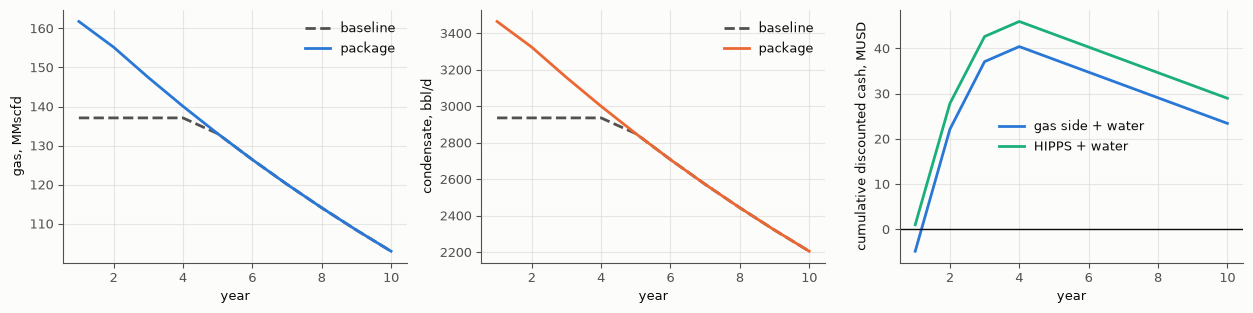

In [9]:
def forecast(gas_cap, cond_add=0.0, decline=DECLINE, wc_start=WC_START, wc_end=WC_END):
    rows = []
    for year in range(1, YEARS + 1):
        potential_gas = G0 * (1.0 - decline) ** (year - 1)
        gas = min(potential_gas, gas_cap)
        cond = gas * CGR_VALUE + cond_add
        wc = wc_start + (wc_end - wc_start) * (year - 1) / (YEARS - 1)
        water = cond * wc / (1.0 - wc)
        rows.append((year, gas, cond, water))
    return pd.DataFrame(rows, columns=["year", "gas", "cond", "water"])


def dcf(
    gas_cap,
    capex,
    deferment=0.0,
    cond_add=0.0,
    gas_price=GAS_PRICE,
    cond_price=COND_PRICE,
    discount=DISCOUNT,
    tax=TAX,
    decline=DECLINE,
    wc_start=WC_START,
    wc_end=WC_END,
    capex_mult=1.0,
    opex_fixed=2.5,
    electricity=0.33,
    water_cost_per_bbl=2.0,
):
    base = forecast(BASE_GAS, 0.0, decline, wc_start, wc_end)
    package = forecast(gas_cap, cond_add, decline, wc_start, wc_end)
    inc_gas = package["gas"] - base["gas"]
    inc_cond = package["cond"] - base["cond"]
    inc_water = package["water"] - base["water"]
    rev_gas = inc_gas * 365.0 * HEATING_VALUE * gas_price / 1e6
    rev_cond = inc_cond * 365.0 * cond_price / 1e6
    opex = opex_fixed + electricity + water_cost_per_bbl * inc_water * 365.0 / 1e6
    ebitda = rev_gas + rev_cond - opex
    dep = capex * capex_mult / YEARS
    ebit = ebitda - dep
    tax_cash = tax * np.maximum(ebit, 0.0)
    cash = ebitda - tax_cash
    disc = (1.0 + discount) ** np.arange(1, YEARS + 1)
    npv = -capex * capex_mult - deferment + float(np.sum(cash / disc))
    cum = np.cumsum(cash) - capex * capex_mult - deferment
    payback = next((index + 1 for index, value in enumerate(cum) if value >= 0.0), None)
    return {
        "npv": npv,
        "payback": payback,
        "cash": cash,
        "cum": cum,
        "gas_pv": float(np.sum(rev_gas / disc)),
        "cond_pv": float(np.sum(rev_cond / disc)),
        "inc_gas": inc_gas,
        "inc_cond": inc_cond,
    }


results = {
    name: dcf(value["cap"], value["capex"], value["deferment"], value["cond_add"])
    for name, value in PACKAGES.items()
}
econ_rows = [
    {
        "package": name,
        "capex MUSD": PACKAGES[name]["capex"],
        "NPV MUSD": value["npv"],
        "payback year": value["payback"],
        "gas PV MUSD": value["gas_pv"],
        "condensate PV MUSD": value["cond_pv"],
    }
    for name, value in results.items()
]
display(pd.DataFrame(econ_rows))

rec = results["Gas side + water"]
hipps = results["HIPPS + water"]
split_rows = [
    {"case": "gas + condensate", "NPV MUSD": rec["npv"]},
    {
        "case": "gas only (condensate price 0)",
        "NPV MUSD": dcf(package_cap, 42.0, cond_price=0.0)["npv"],
    },
    {
        "case": "condensate only (gas price 0)",
        "NPV MUSD": dcf(package_cap, 42.0, gas_price=0.0)["npv"],
    },
    {"case": "pre-tax", "NPV MUSD": dcf(package_cap, 42.0, tax=0.0)["npv"]},
]
display(pd.DataFrame(split_rows))
print(
    "discounted revenue: gas",
    round(rec["gas_pv"], 1),
    "MUSD (",
    round(rec["gas_pv"] / (rec["gas_pv"] + rec["cond_pv"]) * 100.0, 1),
    "%), condensate",
    round(rec["cond_pv"], 1),
    "MUSD (",
    round(rec["cond_pv"] / (rec["gas_pv"] + rec["cond_pv"]) * 100.0, 1),
    "%)",
)

base_profile = forecast(BASE_GAS)
package_profile = forecast(package_cap)
fig, axes = plt.subplots(1, 3, figsize=(12.6, 3.2))
axes[0].plot(
    base_profile["year"], base_profile["gas"], color=MUTED, linestyle="--", label="baseline"
)
axes[0].plot(package_profile["year"], package_profile["gas"], color=PALETTE[0], label="package")
axes[0].set_xlabel("year")
axes[0].set_ylabel("gas, MMscfd")
axes[0].legend(frameon=False)
axes[1].plot(
    base_profile["year"], base_profile["cond"], color=MUTED, linestyle="--", label="baseline"
)
axes[1].plot(package_profile["year"], package_profile["cond"], color=PALETTE[1], label="package")
axes[1].set_xlabel("year")
axes[1].set_ylabel("condensate, bbl/d")
axes[1].legend(frameon=False)
axes[2].plot(np.arange(1, YEARS + 1), rec["cum"], color=PALETTE[0], label="gas side + water")
axes[2].plot(np.arange(1, YEARS + 1), hipps["cum"], color=PALETTE[2], label="HIPPS + water")
axes[2].axhline(0.0, color=INK, linewidth=1.0)
axes[2].set_xlabel("year")
axes[2].set_ylabel("cumulative discounted cash, MUSD")
axes[2].legend(frameon=False)
fig.tight_layout()
plt.show()
plt.close(fig)

## 8. The shutdown schedule

The four-week window is enough for the gas side with the water upgrade and for the HIPPS variant:
the longest task is the four-week water package, and the compressor, internals, HIPPS and flare
work sit inside it in parallel. The fourth stage is a five-week job; it is compressed into the
window with a 3.3 MUSD labour premium. The stabiliser is eight weeks, so it extends the shutdown
by two weeks and defers production; on the year-ten rates that deferment is 10.97 MUSD, before
any manhour premium. The two add-ons together defer 14.27 MUSD.

,package,weeks,class,extension weeks,labour premium MUSD,deferment MUSD
0,Gas side,4.0,fits,0.0,0.0,0.00
1,Gas side + water,4.0,fits,0.0,0.0,0.00
2,HIPPS + water,4.0,fits,0.0,0.0,0.00
3,+ fourth stage,5.0,compressed,0.0,3.3,0.00
4,+ stabiliser,8.0,extends,2.0,0.0,10.97
5,Both add-ons,8.0,extends,2.0,0.0,14.27


deferment basis: two weeks at the year-ten rates = 10.97 MUSD


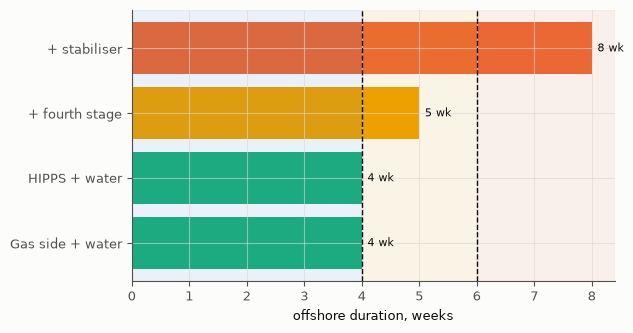

In [10]:
schedule_rows = []
for name, value in PACKAGES.items():
    weeks = value["weeks"]
    if weeks <= 4.0:
        schedule_class = "fits"
        extension = 0.0
        premium = 0.0
    elif weeks <= 6.0:
        schedule_class = "compressed"
        extension = 0.0
        premium = 3.3 if name == "+ fourth stage" else 0.0
    else:
        schedule_class = "extends"
        extension = weeks - 6.0
        premium = 0.0
    schedule_rows.append(
        {
            "package": name,
            "weeks": weeks,
            "class": schedule_class,
            "extension weeks": extension,
            "labour premium MUSD": premium,
            "deferment MUSD": value["deferment"],
        }
    )
display(pd.DataFrame(schedule_rows))
print(
    "deferment basis: two weeks at the year-ten rates =",
    round(
        2.0
        / 52.0
        * (
            current["gas_mmscfd"] * 365.0 * HEATING_VALUE * GAS_PRICE
            + current["bpd"] * 365.0 * COND_PRICE
        )
        / 1e6,
        2,
    ),
    "MUSD",
)

fig, ax = plt.subplots()
tasks = [
    ("Gas side + water", 4.0, PALETTE[2]),
    ("HIPPS + water", 4.0, PALETTE[2]),
    ("+ fourth stage", 5.0, PALETTE[3]),
    ("+ stabiliser", 8.0, PALETTE[1]),
]
for index, (_name, weeks, color) in enumerate(tasks):
    ax.barh(index, weeks, color=color)
    ax.text(weeks + 0.1, index, f"{weeks:.0f} wk", va="center", color=INK, fontsize=8)
ax.axvspan(0.0, 4.0, color=PALETTE[0], alpha=0.08)
ax.axvspan(4.0, 6.0, color=PALETTE[3], alpha=0.08)
ax.axvspan(6.0, 8.4, color=PALETTE[1], alpha=0.08)
ax.axvline(4.0, color=INK, linestyle="--", linewidth=1.0)
ax.axvline(6.0, color=INK, linestyle="--", linewidth=1.0)
ax.set_yticks(range(len(tasks)), [task[0] for task in tasks])
ax.set_xlabel("offshore duration, weeks")
ax.set_xlim(0.0, 8.4)
fig.tight_layout()
plt.show()
plt.close(fig)

## 9. What moves the answer

The gas price is the largest swing: at zero the package is the condensate-only case and loses 36
MUSD; at $8/MMBtu it gains about 54. The decline rate and the capex are next, then the shutdown
slip; the condensate price and the discount rate are small. The HIPPS option is worth about 5.6
MUSD. The message for the client is uncomfortable but clear: the condensate gain is real, but the
project's value is carried by the gas and by fitting the shutdown; a condensate-only case does not
pay, and a two-week slip gives back 11 MUSD, more than half the NPV.

,case,NPV MUSD,change MUSD
0,Water cut -10 pp,19.335405,0.183302
1,Water cut +10 pp,18.878394,-0.273709
2,Discount 8%,20.221638,1.069535
3,Discount 12%,18.034938,-1.117166
4,Condensate 50,13.536453,-5.615650
5,Condensate 90,24.767753,5.615650
6,HIPPS capex,24.779075,5.626972
7,Shutdown slip 2 wk,8.182103,-10.970000
8,Capex -30%,30.903738,11.751635
9,Capex +30%,7.335462,-11.816642


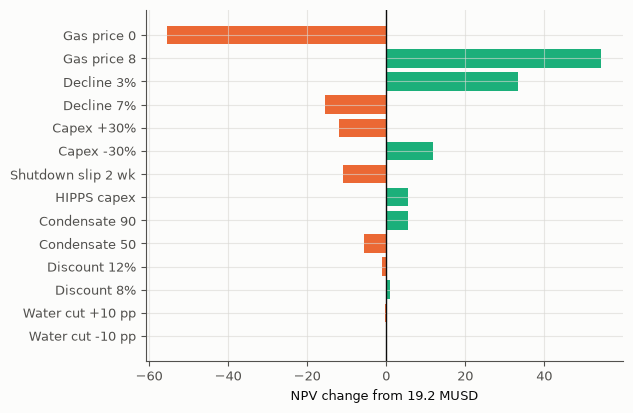

In [11]:
tornado = [
    ("Gas price 0", dcf(package_cap, 42.0, gas_price=0.0)["npv"]),
    ("Gas price 8", dcf(package_cap, 42.0, gas_price=8.0)["npv"]),
    ("Condensate 50", dcf(package_cap, 42.0, cond_price=50.0)["npv"]),
    ("Condensate 90", dcf(package_cap, 42.0, cond_price=90.0)["npv"]),
    ("Capex -30%", dcf(package_cap, 42.0, capex_mult=0.7)["npv"]),
    ("Capex +30%", dcf(package_cap, 42.0, capex_mult=1.3)["npv"]),
    ("Decline 3%", dcf(package_cap, 42.0, decline=0.03)["npv"]),
    ("Decline 7%", dcf(package_cap, 42.0, decline=0.07)["npv"]),
    ("Discount 8%", dcf(package_cap, 42.0, discount=0.08)["npv"]),
    ("Discount 12%", dcf(package_cap, 42.0, discount=0.12)["npv"]),
    (
        "Water cut -10 pp",
        dcf(package_cap, 42.0, wc_start=WC_START - 0.10, wc_end=WC_END - 0.10)["npv"],
    ),
    (
        "Water cut +10 pp",
        dcf(package_cap, 42.0, wc_start=WC_START + 0.10, wc_end=WC_END + 0.10)["npv"],
    ),
    ("Shutdown slip 2 wk", dcf(package_cap, 42.0, deferment=10.97)["npv"]),
    ("HIPPS capex", dcf(hipps_cap, 36.0)["npv"]),
]
tornado = sorted(tornado, key=lambda item: abs(item[1] - rec["npv"]))
tornado_rows = [
    {"case": name, "NPV MUSD": value, "change MUSD": value - rec["npv"]} for name, value in tornado
]
display(pd.DataFrame(tornado_rows))

fig, ax = plt.subplots(figsize=(6.4, 4.2))
for index, (_name, value) in enumerate(tornado):
    delta = value - rec["npv"]
    ax.barh(index, delta, color=PALETTE[2] if delta >= 0.0 else PALETTE[1])
ax.set_yticks(range(len(tornado)), [item[0] for item in tornado])
ax.axvline(0.0, color=INK, linewidth=1.0)
ax.set_xlabel(f"NPV change from {rec['npv']:.1f} MUSD")
fig.tight_layout()
plt.show()
plt.close(fig)

## 10. Recommendation and what it rests on

Recommend the **HIPPS + water package**, with the flare and header upgrade as the fallback if the
SIL-3 safety case is not approved. It is the compressor re-rate, the separator internals, the
relief change and the produced-water upgrade with its coalescer. It fits the four-week shutdown,
costs $36M (or $42M with the flare), returns 24.8 MUSD after tax (19.2 MUSD with the flare) at
10 %, pays back in year one or two, and takes the plateau from 137.1 to 161.8 MMscfd and from
2,936 to about 3,466 bbl/d: 24.7 MMscfd and 530 bbl/d more.

The package is a gas project with a condensate co-product. The discounted revenue is 72.4 MUSD
from gas and 25.8 MUSD from condensate, and on gas alone the package is about -0.5 MUSD; on
condensate alone it is -36.2 MUSD. Neither product alone carries the capital, and the client's
condensate-only objective does not pay at $70/bbl. The recommendation is conditional on the
incremental gas being sold at the assumed price. The fourth stage is close to neutral (15.9
MUSD) and is not recommended for this shutdown; the stabiliser (2.6 MUSD) fails, because its
two-week extension defers 11.0 MUSD. Revisit the fourth stage at a higher condensate price or in
the following shutdown.

**What this rests on.** The field and history are illustrative; the decline is a flat 5 %/yr
forecast, not a reservoir simulation. The separators are equilibrium stages; the compressor is
isentropic with no interstage condensate; the produced-water package is a stated capacity and
cost, not a hydrocyclone model. The relief check is a screening PSV and flare calculation, not a
full relief study; the HIPPS 35 % reduction, the 4/6-week schedule rule, the water-treatment
capacity and the brownfield costs are study assumptions. Flow assurance, hydrates, wax, slugging
and sand are outside the study, as are decommissioning and inflation. The costs are AACE class 4/5
and the long-lead compressor is a schedule risk the deferment model does not carry. Every
calculation is a screening value from a library that ships `unverified` or `partially_verified`
models; none of it is a design deliverable.

## Next

- [Python scripting and Jupyter](https://patrickmockridge.github.io/azoth/manual/using/python.html)
- [Separator capacity assessment](https://patrickmockridge.github.io/azoth/manual/process/separator_capacity_assessment.html)
- [PSV sizing](https://patrickmockridge.github.io/azoth/manual/process/psv_sizing.html) and
  [flare](https://patrickmockridge.github.io/azoth/manual/process/flare.html)